**Diabetes Risk Factor Analysis & Machine Learning**

Project Objective

This project explores patient health measurements to investigate which features are associated with diabetes outcomes and how effectively machine-learning models can classify those outcomes.

Unlike my initial tutorial-based implementation, this independent project focuses on exploratory analysis, data quality, model comparison, and interpretation.

Research Questions

- Which patient characteristics are most strongly associated with diabetes outcomes?

- Are there missing, invalid, or unusual measurements in the dataset?

- How do different preprocessing methods and machine-learning models affect classification performance?

Pima Indians Diabetes Dataset
- this dataset represents women of Pima Indian heritage aged at least 21

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
df = pd.read_csv("/content/diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [26]:
# number of rows and columns
df.shape

(768, 9)

In [27]:
#data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [28]:
#summary statistics
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [29]:
#missing values
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [30]:
#duplicate rows
df.duplicated().sum()

np.int64(0)

In [31]:
#num. of observations in each class
df['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


In [32]:
#df ==0: checks each cell & return true of false
# .sum() counts the true values for each column because python treats true as 1 and false as 0
(df == 0).sum()

,0
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,500


In [33]:
zero_percentage = (df == 0).sum() / len(df) * 100

zero_percentage.round(2)

,0
Pregnancies,14.45
Glucose,0.65
BloodPressure,4.56
SkinThickness,29.56
Insulin,48.70
BMI,1.43
DiabetesPedigreeFunction,0.00
Age,0.00
Outcome,65.10


### Data Quality Analysis: Identifying Potential Missing Values

In [34]:
features = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

zero_percentages = (df[features] == 0).sum() / len(df) * 100

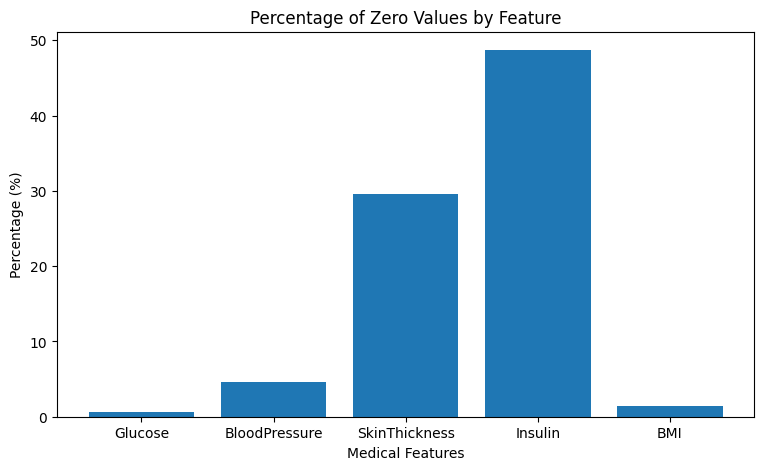

In [35]:
plt.figure(figsize=(9, 5))

plt.bar(features, zero_percentages.values)

plt.title("Percentage of Zero Values by Feature")
plt.ylabel("Percentage (%)")
plt.xlabel("Medical Features")
plt.show()

are aero insulin measurements equally common among patients with and without diabetes?

In [36]:
df['Insulin_Zero'] = df['Insulin'] == 0

In [38]:
#groupby('outcome') separates patients into the negative 0 and positive 1 diabetes outcome groups
#['insulin_zero'] selects our new column
#.mean() calculates the proportion of true values in each group
#*100 converts the proportion into a percentage

df.groupby('Outcome')['Insulin_Zero'].mean() * 100

,Insulin_Zero
Outcome,
0,47.200000
1,51.492537


In [40]:
insulin_zero_by_outcome = (df.groupby('Outcome')['Insulin_Zero'].mean() *100)
print(insulin_zero_by_outcome)

Outcome
0    47.200000
1    51.492537
Name: Insulin_Zero, dtype: float64


Approximately 47.2% of patients with negative diabetes outcomes and 51.5% of patients with positive outcomes have insulin measurements recorded as zero. This suggests that potentially missing insulin measurements are slightly more common in the positive outcome group. However, the difference is relatively small, and further investigation is needed to determine whether this pattern is meaningful

In [41]:
df.groupby('Outcome')['Glucose'].describe()

,count,mean,std,min,25%,50%,75%,max
Outcome,,,,,,,,
0,500.0,109.980000,26.141200,0.0,93.0,107.0,125.0,197.0
1,268.0,141.257463,31.939622,0.0,119.0,140.0,167.0,199.0


patients with positive diabetes outcomes tend to have higher glucose measurements than patients with negative outcomes in this dataset

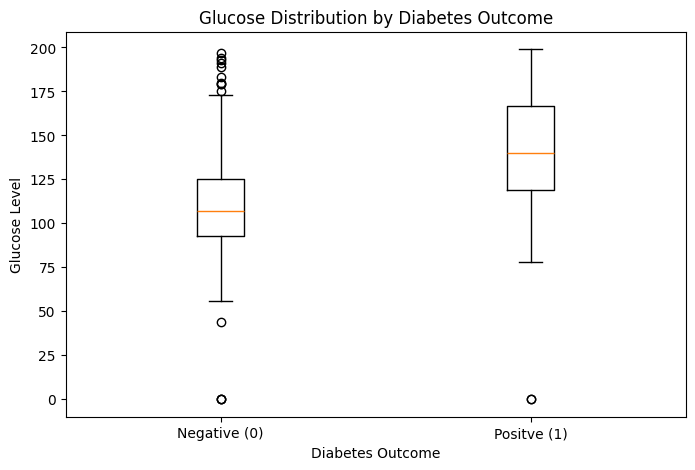

In [45]:
glucose_negative = df[df['Outcome'] == 0]['Glucose']
glucose_positive = df[df['Outcome'] == 1]['Glucose']

fig= plt.figure(figsize=(8, 5))

ax=fig.add_subplot()
bp=ax.boxplot([glucose_negative, glucose_positive], tick_labels=['Negative (0)', 'Positve (1)'])

plt.title("Glucose Distribution by Diabetes Outcome")
plt.xlabel("Diabetes Outcome")
plt.ylabel("Glucose Level")
plt.show()

- the positive group generally has higher glucose measurements
- the positive group's box is taller, meaning its middle 50% of glucose values are more spead out
- the negative group has several high-glucose outliers "the small circles above the whisker"
- both groups contain glucose values of zero, visible as points at the bottom. these may represent missing measurements
- the two group's glucose distributions overlap, so glucose alone doesn't perfectly separate the outcomes

**do patients with positive diabetes outcomes tend to have higher BMI values?**

In [46]:
df.groupby('Outcome')['BMI'].describe()

,count,mean,std,min,25%,50%,75%,max
Outcome,,,,,,,,
0,500.0,30.304200,7.689855,0.0,25.4,30.05,35.300,57.3
1,268.0,35.142537,7.262967,0.0,30.8,34.25,38.775,67.1


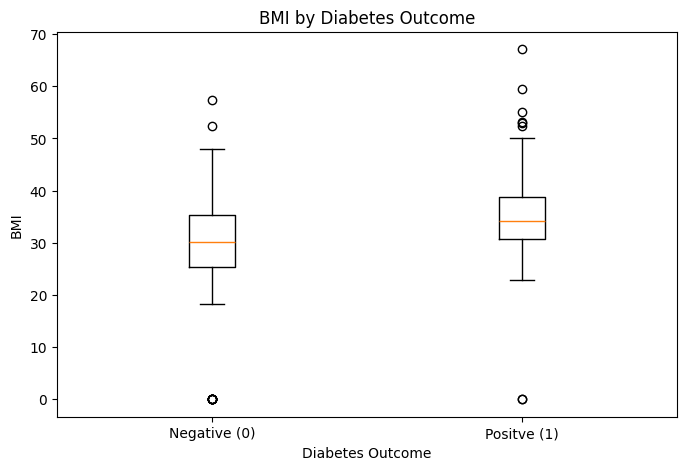

In [47]:
BMI_negative = df[df['Outcome'] == 0]['BMI']
BMI_positive = df[df['Outcome'] == 1]['BMI']

fig= plt.figure(figsize=(8, 5))

ax=fig.add_subplot()
bp=ax.boxplot([BMI_negative, BMI_positive], tick_labels=['Negative (0)', 'Positve (1)'])

plt.title("BMI by Diabetes Outcome")
plt.xlabel("Diabetes Outcome")
plt.ylabel("BMI")
plt.show()

The BMI distribution shows that patients with positive diabetes outcomes generally have higher BMI values than those with negative outcomes. The median BMI is 34.25 for the positive group and 30.05 for the negative group. However, the distributions overlap, indicating that BMI alone cannot perfectly distinguish between the two groups. Both groups also contain implausible zero values that require further investigation.

**Do patients with positive diabetes outcomes tend to be older than patients with negative outcomes?**

In [53]:
df.groupby('Outcome')['Age'].describe()

,count,mean,std,min,25%,50%,75%,max
Outcome,,,,,,,,
0,500.0,31.190000,11.667655,21.0,23.0,27.0,37.0,81.0
1,268.0,37.067164,10.968254,21.0,28.0,36.0,44.0,70.0


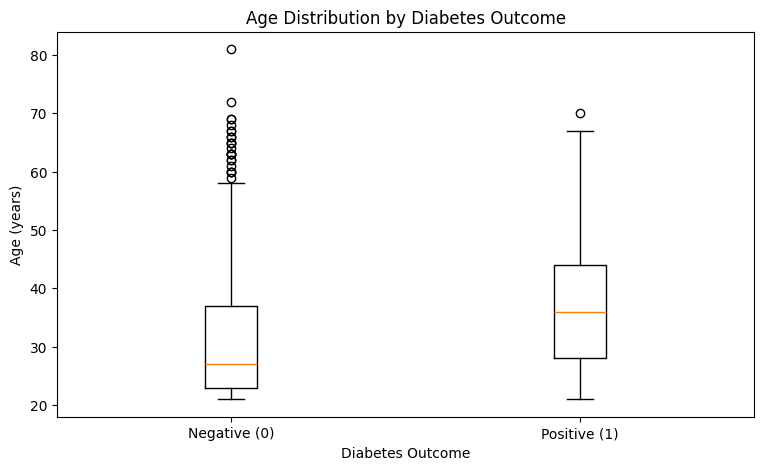

In [56]:
age_negative = df[df['Outcome'] == 0]['Age']
age_positive = df[df['Outcome'] == 1]['Age']

plt.figure(figsize=(9, 5))

plt.boxplot(
    [age_negative, age_positive],
    tick_labels=['Negative (0)', 'Positive (1)']
)


plt.title("Age Distribution by Diabetes Outcome")
plt.ylabel("Age (years)")
plt.xlabel("Diabetes Outcome")
plt.show()

the horizontal line inside each box represents the median

In [57]:
#.corr() calculates the pearson correlation coefficient, which measures linear relationships


correlation_matrix = df.corr()

correlation_matrix

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,Insulin_Zero
Pregnancies,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898,0.170156
Glucose,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581,-0.045295
BloodPressure,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068,-0.082212
SkinThickness,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752,-0.551775
Insulin,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548,-0.675075
BMI,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695,-0.129748
DiabetesPedigreeFunction,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844,-0.166357
Age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356,0.211885
Outcome,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000,0.040934
Insulin_Zero,0.170156,-0.045295,-0.082212,-0.551775,-0.675075,-0.129748,-0.166357,0.211885,0.040934,1.000000


Among glucose, BMI, and age, glucose has the strongest positive linear association with diabetes outcome in this dataset

In [59]:
correlation_matrix['Outcome'].sort_values(ascending=False)

,Outcome
Outcome,1.000000
Glucose,0.466581
BMI,0.292695
Age,0.238356
Pregnancies,0.221898
DiabetesPedigreeFunction,0.173844
Insulin,0.130548
SkinThickness,0.074752
BloodPressure,0.065068


In [60]:
correlation_matrix = df.drop(
    columns=['Insulin_Zero']
).corr()

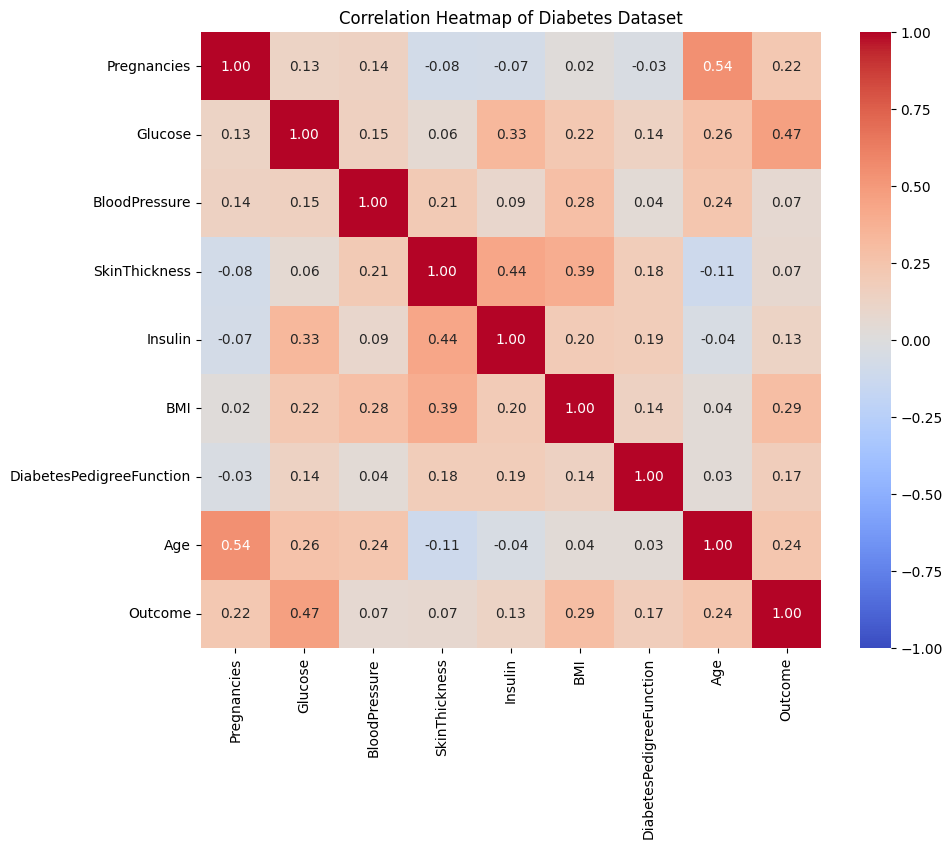

In [63]:
plt.figure(figsize=(10, 8))

sns.heatmap(correlation_matrix,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            vmin=-1,
            vmax=1,
            center=0)

plt.title("Correlation Heatmap of Diabetes Dataset")
plt.show()

Argument	Purpose
- correlation_matrix	The data we want to visualize
- annot=True	Displays the correlation numbers inside each square
- cmap='coolwarm'	Uses a diverging color palette
- fmt='.2f'	Displays numbers with two decimal places
- vmin=-1, vmax=1	Keeps the color scale between −1 and +1

### Key Findings from Exploratory Data Analysis

The dataset contains 768 observations and eight medical predictor features. Although no missing values were detected using `isnull()`, several medical features contain physiologically implausible zero values.

Approximately 48.7% of insulin measurements are zero, indicating a substantial potential missing-data problem.

Patients with positive diabetes outcomes generally have higher glucose, BMI, and age values than patients with negative outcomes.

The correlation analysis identified glucose as the feature with the strongest positive linear association with diabetes outcome (r ≈ 0.47). However, correlation does not establish causation or predictive performance.

These findings suggest that careful preprocessing and model evaluation are necessary before drawing further conclusions.

In [69]:
zero_cols = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

In [64]:
X = df.drop(columns=['Outcome', 'Insulin_Zero'])
y = df['Outcome']

In [66]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
#stratify =y =>helps preserve similar proportions of positive and negative cases in both sets

In [70]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer

def replace_invalid_zeros(X):
    return X.replace(0, np.nan)

medical_pipeline = Pipeline([
    ('zeros_to_nan', FunctionTransformer(replace_invalid_zeros)),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('medical', medical_pipeline, zero_cols),
    ('other', StandardScaler(), [
        'Pregnancies',
        'DiabetesPedigreeFunction',
        'Age'
    ])
])

replace_invalid_zeros converts suspicious zero measurements into missing values.



SimpleImputer replaces those missing measurements with the training-set median.



StandardScaler standardizes features, which is useful for models such as Logistic Regression and SVM.



The pipeline ensures imputation and scaling are learned from training data, not from the test set.

In [71]:
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (614, 8)
Testing: (154, 8)


**Train our first model*

In [72]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('medical',
                                                  Pipeline(steps=[('zeros_to_nan',
                                                                   FunctionTransformer(func=<function replace_invalid_zeros at 0x7cb6e5a4a0c0>)),
                                                                  ('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Glucose', 'BloodPressure',
                                                   'SkinThickness', 'Insulin',
                                                   'BMI']),
                                                 ('other', StandardScaler(),
                                                  ['Pregnancies',
                                                   'DiabetesPedigreeFunction',
                                                   'Age'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

preprocessing: Handles invalid zeros, imputes missing measurements, and scales the features.



LogisticRegression: Learns relationships between those features and diabetes outcomes.



.fit(X_train, y_train): Fits the preprocessing steps and trains the model using only training data.

In [73]:
from sklearn.metrics import accuracy_score, recall_score, f1_score

y_pred = logistic_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))

Accuracy: 0.7077922077922078
Recall: 0.5
F1-score: 0.5454545454545454


Accuracy = 70.78%

the model correctly classified approximately 71% of patients in the test set.

Recall = 50%

Of all patients labeled positive for diabetes in the test set, the model correctly identified only half.


F1-score = 54.55%

F1 balances precision and recall. the result indicates room for improvement, especially in identifying positive cases.

In [74]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score

svm_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', SVC(kernel='linear'))
])

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, svm_pred))
print("Recall:", recall_score(y_test, svm_pred))
print("F1-score:", f1_score(y_test, svm_pred))

Accuracy: 0.7012987012987013
Recall: 0.48148148148148145
F1-score: 0.5306122448979592


In [75]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1-score:", f1_score(y_test, rf_pred))

Accuracy: 0.7272727272727273
Recall: 0.5555555555555556
F1-score: 0.5882352941176471


In [76]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

models = {
    'Logistic Regression': logistic_model,
    'SVM': svm_model,
    'Random Forest': rf_model
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            'accuracy': 'accuracy',
            'recall': 'recall',
            'f1': 'f1',
            'roc_auc': 'roc_auc'
        }
    )

    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean()
    })

cv_results = pd.DataFrame(results)
display(cv_results.round(3))

,Model,Accuracy,Recall,F1,ROC-AUC
0,Logistic Regression,0.788,0.575,0.655,0.843
1,SVM,0.788,0.570,0.652,0.845
2,Random Forest,0.764,0.584,0.632,0.817


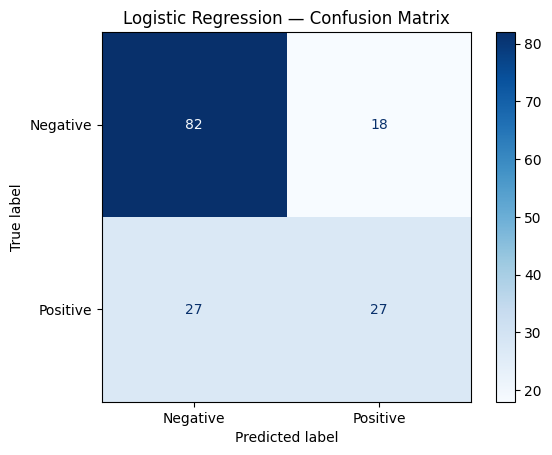

In [77]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    display_labels=['Negative', 'Positive'],
    cmap='Blues'
)

plt.title("Logistic Regression — Confusion Matrix")
plt.show()

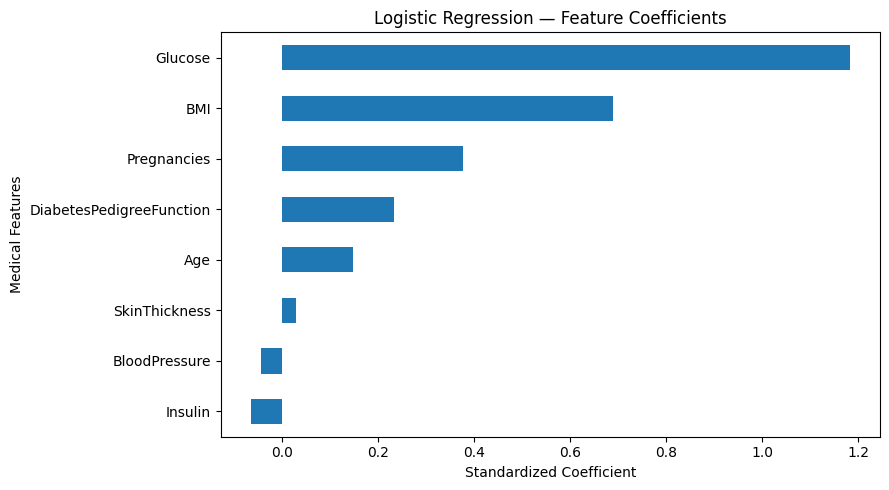

In [80]:


# Feature order used by ColumnTransformer
feature_names = zero_cols + [
    'Pregnancies',
    'DiabetesPedigreeFunction',
    'Age'
]

# Get Logistic Regression coefficients
coefficients = logistic_model.named_steps[
    'classifier'
].coef_[0]

# Create a Series
feature_importance = pd.Series(
    coefficients,
    index=feature_names
).sort_values()

# Plot
plt.figure(figsize=(9, 5))

feature_importance.plot(kind='barh')

plt.title("Logistic Regression — Feature Coefficients")
plt.xlabel("Standardized Coefficient")
plt.ylabel("Medical Features")
plt.tight_layout()
plt.show()

## Conclusion

This project investigated relationships between patient health measurements and diabetes outcomes using exploratory data analysis and machine-learning classification.

**Key findings:**

- Glucose, BMI, and age tended to be higher among patients with positive diabetes outcomes.
- Several medical measurements contained implausible zero values, particularly insulin, where approximately 48.7% of observations were recorded as zero.
- Glucose showed the strongest positive Pearson correlation with diabetes outcome (r ≈ 0.47).
- Three classification algorithms were compared: Logistic Regression, Support Vector Machine, and Random Forest.
- Logistic Regression achieved the highest mean F1-score (0.655) during five-fold cross-validation, while SVM achieved a slightly higher mean ROC-AUC (0.845 versus 0.843).
- On the held-out test set, Logistic Regression achieved 70.78% accuracy and 50% recall, missing 27 of 54 positive cases.
- Logistic Regression coefficients identified glucose and BMI as the strongest positive contributors to its linear predictions.

### Limitations

The dataset contains only 768 observations from a specific population, limiting generalizability. Potentially missing measurements, class imbalance, and uncertainty around model performance require further investigation.

The models were also examined on the test set during development, so the test-set results should not be treated as an entirely independent final assessment.

This project demonstrates machine-learning methodology and exploratory healthcare data analysis. The resulting models are experimental and are not suitable for clinical diagnosis or screening.